# DSCI 552 - Homework 6

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## AI Use Disclosure

I used GitHub Copilot with GPT-6.1 Sol to assist with code validation, review of written answers, and understanding the reasoning behind implementation choices and code updates in this homework.

The assistance was used as a review and learning aid, rather than as independent verification of correctness. I personally wrote all code and written responses. I reviewed feedback provided by GitHub Copilot and auto correct when building out each notebook.

Much like I do in my full time profession as data engineer at GitHub I used Copiolot, and specifically GPT-6.1 Sol to review answers. When it was available I used auto correct that is powered by AI and uses GitHub copilot to assist and validate.

## 1. Tree-Based Methods

### 1(a) - Download the APS Failure data from: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks . The dataset contains a training set and a test set. The training set contains 60,000 rows, of which 1,000 belong to the positive class and 171 columns, of which one is the class column. All attributes are nu-meric.

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data")

train_df = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training Shape: ", train_df.shape)
print("Testing Shape: ", test_df.shape)
print("Training Class Counts:")
print(train_df["class"].value_counts())

display(train_df.head())

Training Shape:  (60000, 171)
Testing Shape:  (16000, 171)
Training Class Counts:
class
neg    59000
pos     1000
Name: count, dtype: int64


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### 1(b) - Data Preparation - This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea. 

#### 1(b)(i) - Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

In [18]:
from sklearn.impute import SimpleImputer

x_train_raw = train_df.drop(columns=["class"])
x_test_raw = test_df.drop(columns=["class"])

y_train = train_df["class"].copy()
y_test = test_df["class"].copy()

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

x_train = pd.DataFrame(
    imputer.fit_transform(x_train_raw),
    columns=x_train_raw.columns,
    index=x_train_raw.index
)

x_test = pd.DataFrame(
    imputer.transform(x_test_raw),
    columns=x_test_raw.columns,
    index=x_test_raw.index
)

print("Training missing values before:", x_train_raw.isna().sum().sum())
print("Training missing values after:", x_train.isna().sum().sum())
print("Test missing values before:", x_test_raw.isna().sum().sum())
print("Test missing values after:", x_test.isna().sum().sum())

Training missing values before: 850015
Training missing values after: 0
Test missing values before: 228680
Test missing values after: 0


**Answer**: Common ways to fill missing values include using a features mean or median, using values from similar observations or predicting missing values from other features. I chose median imputation becasue it is simple, fast and less affected by extreme values than the mean.

#### 1(b)ii. For each of the 170 features, calculate the coefficient of variation CV = sm ,where s is sample standard deviation and m is sample mean.

In [19]:
import numpy as np
import pandas as pd

feature_means = x_train.mean()
feature_stds = x_train.std(ddof=1)

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Sample Standard Deviation": feature_stds,
    "CV": feature_stds / feature_means.replace(0, np.nan)
})

display(cv_table)

,Mean,Sample Standard Deviation,CV
aa_000,5.933650e+04,1.454301e+05,2.450938
ab_000,1.625000e-01,1.687318e+00,10.383494
ac_000,3.362258e+08,7.767625e+08,2.310241
ad_000,1.434383e+05,3.504525e+07,244.322816
ae_000,6.535000e+00,1.581479e+02,24.200137
...,...,...,...
ee_007,3.428586e+05,1.718666e+06,5.012754
ee_008,1.372212e+05,4.472145e+05,3.259079
ee_009,8.295099e+03,4.721249e+04,5.691612
ef_000,8.646667e-02,4.268570e+00,49.366659


#### 1(b)(iii) - Plot a correlation matrix for your features using pandas or any other tool.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = x_train.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.show()

#### 1(b)(iv) - Pick b√170c features with highest CV , and make scatter plots and box plotsfor them, similar to those on p. 129 of ISLR. Can you draw conclusions aboutsignificance of those features, just by the scatter plots? This does not meanthat you will only use those features in the following questions. We picked them only for visualization.

In [ ]:
import numpy as np

n_features = int(np.sqrt(170))

top_features = (
    cv_table["CV"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .nlargest(n_features)
    .index
)

display(cv_table.loc[top_features].sort_values("CV", ascending=False))

,Mean,Sample Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


In [ ]:
import numpy as np

n_features = int(np.sqrt(170))

top_features = (
    cv_table["CV"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .nlargest(n_features)
    .index
)

display(cv_table.loc[top_features].sort_values("CV", ascending=False))

,Mean,Sample Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


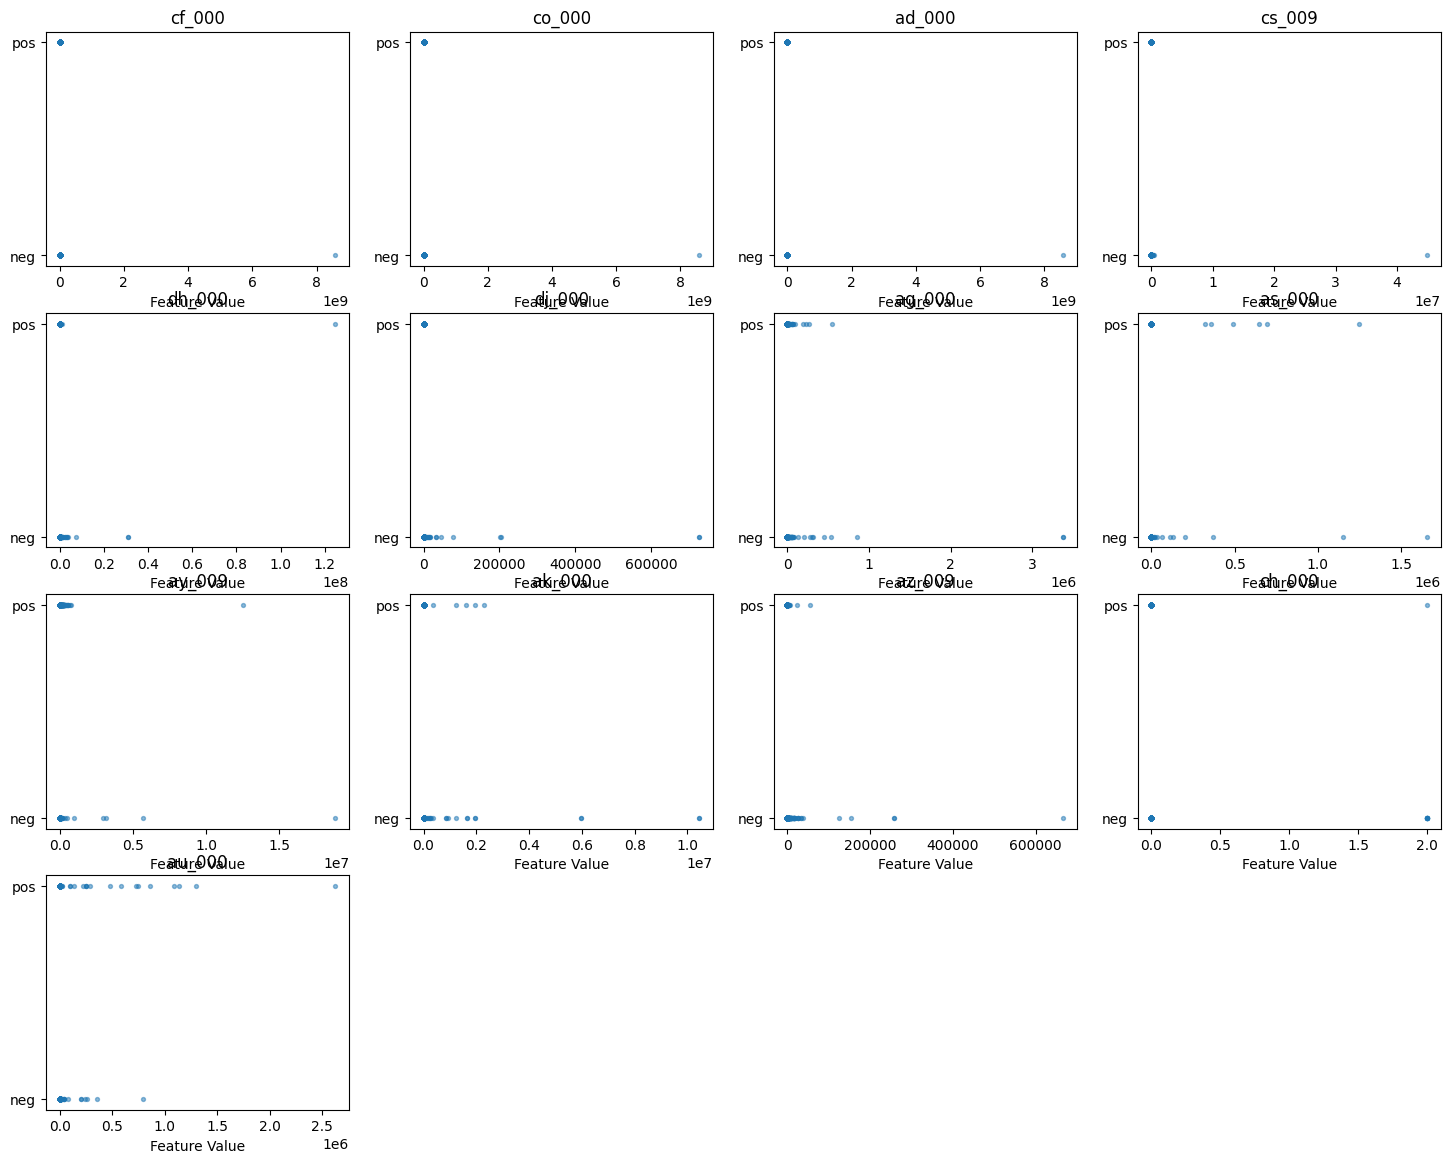

In [ ]:
y_binary = y_train.map({"neg": 0, "pos": 1})

fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, feature in zip(axes.flat, top_features):
    ax.scatter(
        x_train[feature],
        y_binary,
        alpha=0.5,
        s=8
    )
    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_yticks([0, 1], labels=["neg", "pos"])

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

plt.show()

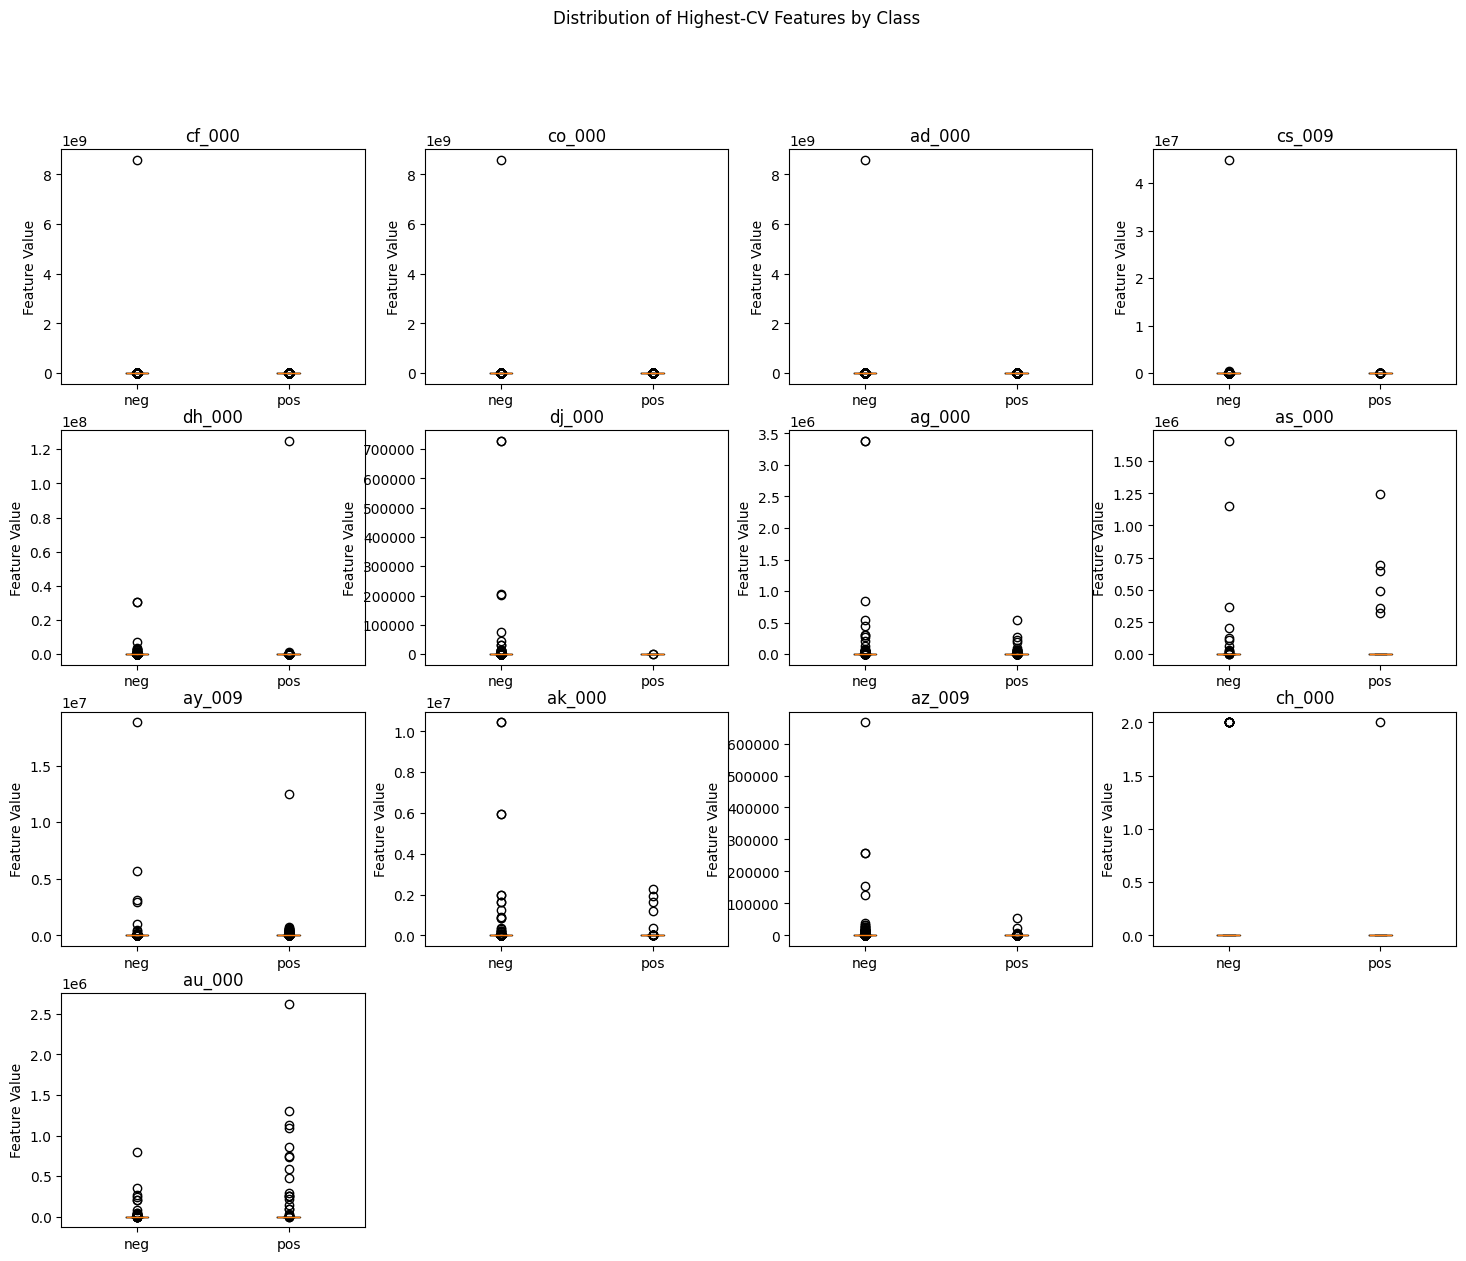

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))

for ax, feature in zip(axes.flat, top_features):
    values_by_class = [
        x_train.loc[y_train == "neg", feature],
        x_train.loc[y_train == "pos", feature]
    ]
    ax.boxplot(values_by_class)
    ax.set_xticks([1, 2], labels=["neg", "pos"])
    ax.set_title(feature)
    ax.set_ylabel("Feature Value")

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)

fig.suptitle("Distribution of Highest-CV Features by Class")
plt.show()

**Answer**: The plots may show differences between positive and negative cases, but they cannot tell us whether those differences are statistically significant. There are also many more negative cases, which can make the plots harder to interpret. A high CV means a feature varies a lot compared with its average, not that it is useful for predicting failures. I will still use all 170 featurs in later models.

#### 1(b)(v) - Determine the number of positive and negative data. Is this data set imbalanced?

In [ ]:
class_counts = y_train.value_counts().reindex(
    ["neg", "pos"], fill_value=0
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / class_counts.sum() * 100
})

display(class_summary)

,Count,Percentage
class,,
neg,59000,98.333333
pos,1000,1.666667


the training set is very imbalanced. It has 59,000 negative observations and 1000 positive observations. A classifier that always predicts negative would achieve approximately 98.33% accurace while detecting no positive cases. This means the accueacy alone is insufficient for evaluation model performance.